In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [2]:
print("Pytorch Version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:",torch.cuda.get_device_name(0))


Pytorch Version: 2.10.0+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [3]:
transform=transforms.ToTensor()

train_dataset=torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

test_dataset=torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    transform=transform,
    download=True
)

print("Training samples:",len(train_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 50000
Testing samples: 10000


In [5]:
image, label= train_dataset[0]

print("image Shape:",image.shape)
print("Label:",label)

image Shape: torch.Size([3, 32, 32])
Label: 6


In [6]:
classes=train_dataset.classes
print("Class:",classes[label])

Class: frog


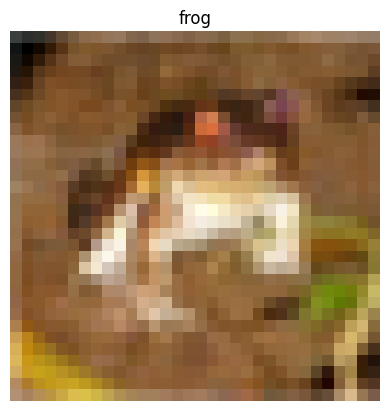

In [7]:
plt.imshow(image.permute(1,2,0))
plt.title(classes[label])
plt.axis("off")
plt.show()

In [8]:
train_loader=torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader=torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [9]:
images, labels=next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])


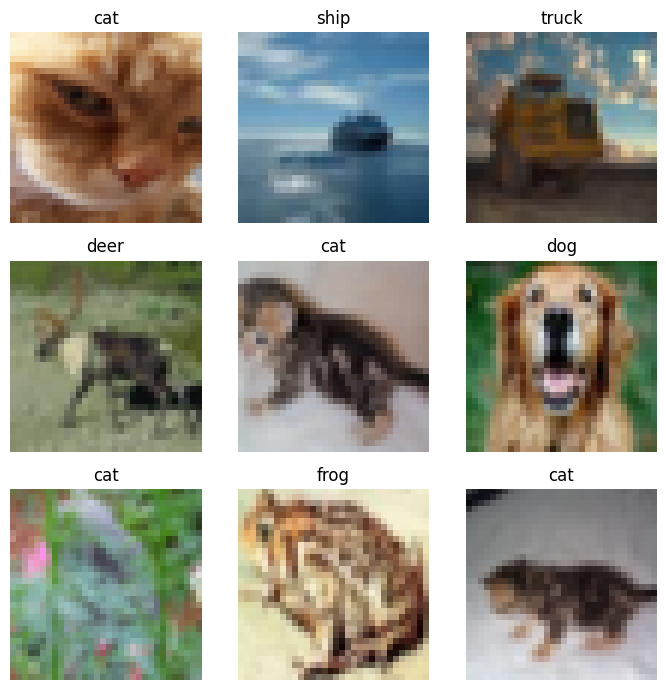

In [10]:
fig, axes= plt.subplots(3,3,figsize=(7,7))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1,2,0))
    ax.set_title(classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import torch.nn as nn

In [12]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1= nn.Conv2d(in_channels=3, 
                              out_channels=32,
                              kernel_size=3,
                              padding=1
                              )

        self.bn1= nn.BatchNorm2d(32)
        self.relu=nn.ReLU()
        self.pool=nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.gap = nn.AdaptiveAvgPool2d((1,1))

        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x=self.conv1(x)
        x=self.bn1(x)
        x=self.relu(x)
        x=self.pool(x)

        x=self.conv2(x)
        x=self.bn2(x)
        x=self.relu(x)
        x=self.pool(x)

        x=self.conv3(x)
        x=self.bn3(x)
        x=self.relu(x)

        x=self.gap(x)
        x=torch.flatten(x,1)

        x=self.fc(x)

        return x


In [13]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print(device)

cuda


In [14]:
model = SmallCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [15]:
print(next(model.parameters()).device)

cuda:0


In [16]:
num_epochs = 10

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {train_loss:.4f} "
        f"Test Accuracy: {accuracy:.2f}%"
    )

Epoch [1/10] Loss: 1.4141 Test Accuracy: 38.08%
Epoch [2/10] Loss: 1.1077 Test Accuracy: 45.89%
Epoch [3/10] Loss: 0.9871 Test Accuracy: 55.25%
Epoch [4/10] Loss: 0.9120 Test Accuracy: 63.25%
Epoch [5/10] Loss: 0.8516 Test Accuracy: 55.65%
Epoch [6/10] Loss: 0.8013 Test Accuracy: 57.83%
Epoch [7/10] Loss: 0.7629 Test Accuracy: 55.72%
Epoch [8/10] Loss: 0.7280 Test Accuracy: 61.45%
Epoch [9/10] Loss: 0.6944 Test Accuracy: 65.79%
Epoch [10/10] Loss: 0.6672 Test Accuracy: 66.96%
